In [ ]:
import pandas as pd

df = pd.read_csv('Cleaned_DataSet.csv')

# Afficher les 5 premières lignes pour vérifier
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Transaction Date
0,TXN_1961373,coffee,2.0,2.0,4.0,2023-09-08
1,TXN_4977031,cake,4.0,3.0,12.0,2023-05-16
2,TXN_4271903,cookie,4.0,1.0,8.0,2023-07-19
3,TXN_7034554,salad,2.0,5.0,10.0,2023-04-27
4,TXN_3160411,coffee,2.0,2.0,4.0,2023-06-11


In [ ]:
# 1. Voir la taille du dataset
print("Nombre de lignes et colonnes :", df.shape)
print("-" * 50)

# 2. Voir le nom des colonnes et le type de données
print(df.info())
print("-" * 50)

# 3. Afficher des statistiques de base (moyenne, min, max des prix, etc.)
display(df.describe())

Nombre de lignes et colonnes : (9741, 6)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9741 entries, 0 to 9740
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    9741 non-null   object 
 1   Item              9741 non-null   object 
 2   Quantity          9741 non-null   float64
 3   Price Per Unit    9741 non-null   float64
 4   Total Spent       9741 non-null   float64
 5   Transaction Date  9741 non-null   object 
dtypes: float64(3), object(3)
memory usage: 456.7+ KB
None
--------------------------------------------------


,Quantity,Price Per Unit,Total Spent
count,9741.000000,9741.000000,9741.000000
mean,2.977312,2.901499,8.449287
std,1.366510,1.217124,5.307016
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,20.000000


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Charger les données (remplace par le nom exact de ton fichier dans Colab)
df = pd.read_csv('Cleaned_DataSet.csv')

# 2. Convertir la colonne date en vrai format Date (et non du texte)
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], dayfirst=False) # Le format semble être Mois/Jour/Année

# 3. Extraire l'heure et le jour de la semaine
df['Heure'] = df['Transaction Date'].dt.hour
df['Jour_Semaine'] = df['Transaction Date'].dt.day_name()

print("Données prêtes !")
df.head()

Données prêtes !


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Transaction Date,Heure,Jour_Semaine
0,TXN_1961373,coffee,2.0,2.0,4.0,2023-09-08,0,Friday
1,TXN_4977031,cake,4.0,3.0,12.0,2023-05-16,0,Tuesday
2,TXN_4271903,cookie,4.0,1.0,8.0,2023-07-19,0,Wednesday
3,TXN_7034554,salad,2.0,5.0,10.0,2023-04-27,0,Thursday
4,TXN_3160411,coffee,2.0,2.0,4.0,2023-06-11,0,Sunday


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

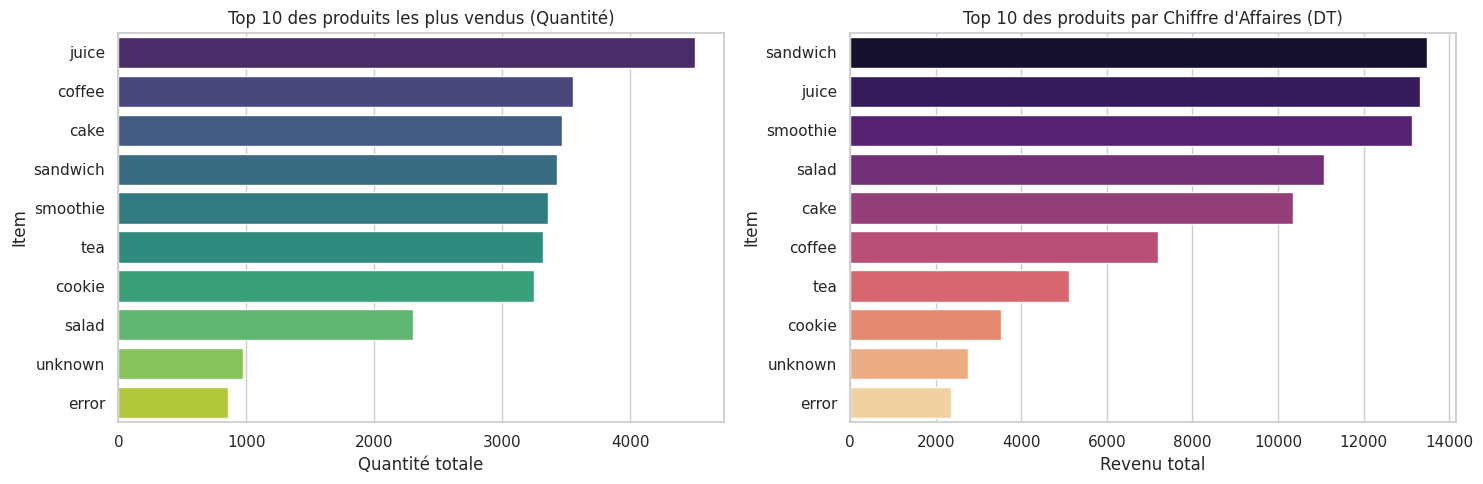

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Configurer le style
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- GRAPHIQUE 1 : Top 10 des produits par Quantité ---
top_produits = df.groupby('Item')['Quantity'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_produits.values, y=top_produits.index, ax=axes[0], hue=top_produits.index, palette="viridis", legend=False)
axes[0].set_title("Top 10 des produits les plus vendus (Quantité)")
axes[0].set_xlabel("Quantité totale")

# --- GRAPHIQUE 2 : Top 10 des produits par Chiffre d'Affaires ---
top_ca = df.groupby('Item')['Total Spent'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_ca.values, y=top_ca.index, ax=axes[1], hue=top_ca.index, palette="magma", legend=False)
axes[1].set_title("Top 10 des produits par Chiffre d'Affaires (DT)")
axes[1].set_xlabel("Revenu total")

plt.tight_layout()
plt.show()

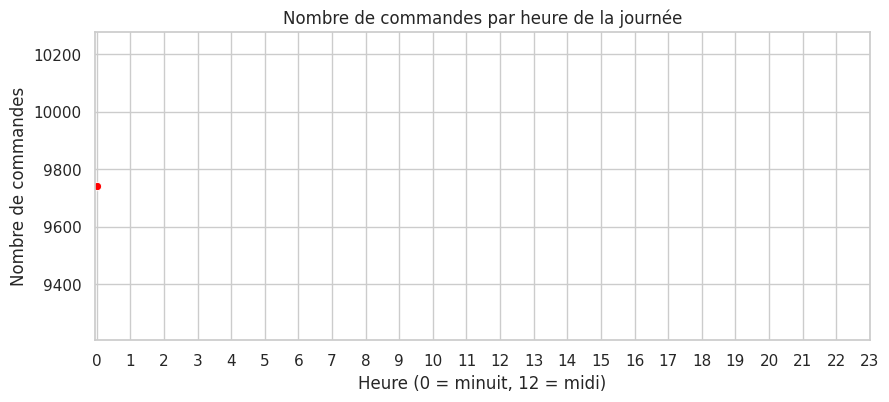

In [ ]:
# Créer un graphique pour les heures de pointe
plt.figure(figsize=(10, 4))
commandes_par_heure = df['Heure'].value_counts().sort_index()

# On utilise un graphique en ligne pour bien voir l'évolution au fil de la journée
sns.lineplot(x=commandes_par_heure.index, y=commandes_par_heure.values, marker="o", color="red", linewidth=2)
plt.title("Nombre de commandes par heure de la journée")
plt.xlabel("Heure (0 = minuit, 12 = midi)")
plt.ylabel("Nombre de commandes")
plt.xticks(range(0, 24)) # Afficher toutes les heures de 0 à 23
plt.show()

In [ ]:
!pip install mlxtend

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# 1. On regroupe les produits par date de transaction (pour simuler un panier client)
# On suppose que si c'est la même date, c'est le même ticket de caisse
paniers = df.groupby('Transaction Date')['Item'].apply(list).tolist()

# 2. On transforme ces listes en matrice True/False (One-Hot Encoding)
te = TransactionEncoder()
te_ary = te.fit(paniers).transform(paniers)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# 3. On applique l'algorithme Apriori
# min_support=0.05 signifie : on cherche des combinaisons présentes dans au moins 5% des tickets
frequent_itemsets = apriori(df_encoded, min_support=0.05, use_colnames=True)

# 4. On génère les règles d'association
# min_threshold=0.3 signifie : on cherche des règles vraies à au moins 30% du temps
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)

# 5. Trier par "Lift" (la force de l'association) et afficher le top 10
rules = rules.sort_values(by='lift', ascending=False)
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
41548,"(coffee, error, sandwich, unknown, salad)","(smoothie, cake, juice)",0.221918,0.941860,1.094838
46807,"(coffee, cookie, error, sandwich, unknown, salad)","(smoothie, cake, juice)",0.208219,0.938272,1.090666
49236,"(coffee, error, sandwich, unknown, tea, salad)","(smoothie, cake, juice)",0.208219,0.938272,1.090666
27676,"(salad, coffee, error, unknown)","(smoothie, cake, juice)",0.241096,0.936170,1.088223
28401,"(coffee, error, sandwich, unknown, salad)","(smoothie, cake)",0.224658,0.953488,1.087573
41512,"(coffee, error, sandwich, unknown, salad, juice)","(smoothie, cake)",0.221918,0.952941,1.086949
50422,"(coffee, cookie, error, sandwich, unknown, tea...","(smoothie, cake, juice)",0.194521,0.934211,1.085945
41258,"(coffee, error, sandwich, tea, salad, juice)","(smoothie, cake)",0.372603,0.951049,1.084790
41449,"(smoothie, cake)","(coffee, error, sandwich, tea, salad, juice)",0.372603,0.425000,1.084790
42283,"(coffee, error, sandwich, unknown, tea, salad)","(smoothie, cake)",0.210959,0.950617,1.084298


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

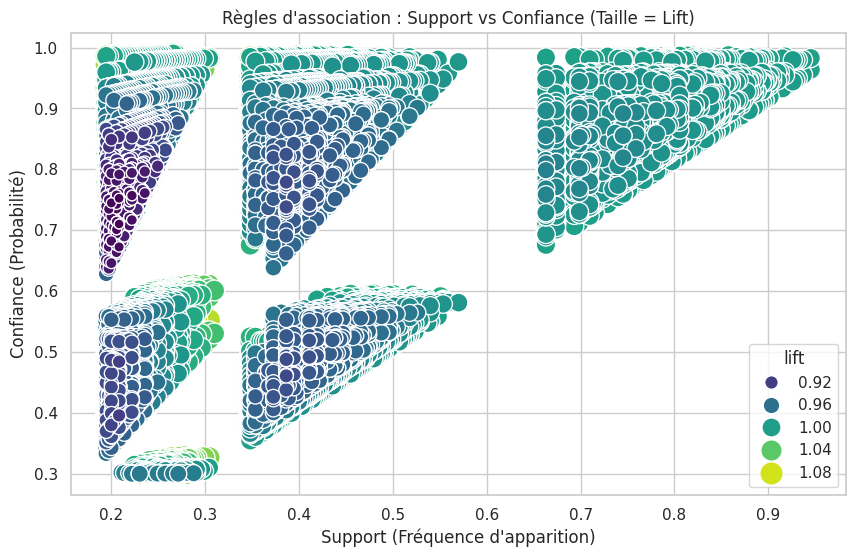

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Créer un scatter plot (nuage de points) des règles
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rules, x='support', y='confidence', size='lift', hue='lift', palette='viridis', sizes=(50, 300))
plt.title("Règles d'association : Support vs Confiance (Taille = Lift)")
plt.xlabel("Support (Fréquence d'apparition)")
plt.ylabel("Confiance (Probabilité)")
plt.show()


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Chargement du jeu de données...
Génération des règles d'association...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

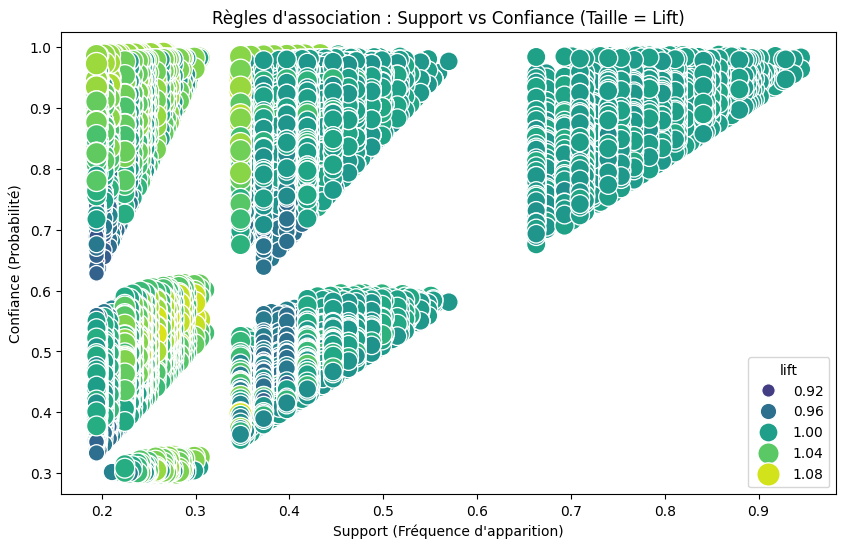

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# S'assurer que le DataFrame 'df' est disponible en mémoire
try:
    df
except NameError:
    print("Chargement du jeu de données...")
    df = pd.read_csv('Cleaned_DataSet.csv')
    df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], dayfirst=False)

# S'assurer que les variables et règles sont générées
try:
    rules
except NameError:
    print("Génération des règles d'association...")
    # Recréer les paniers et générer les règles
    paniers = df.groupby('Transaction Date')['Item'].apply(list).tolist()
    te = TransactionEncoder()
    te_ary = te.fit(paniers).transform(paniers)
    df_encoded = pd.DataFrame(te_ary, columns=te.columns_)
    frequent_itemsets = apriori(df_encoded, min_support=0.05, use_colnames=True)
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)

# Créer un scatter plot (nuage de points) des règles
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rules, x='support', y='confidence', size='lift', hue='lift', palette='viridis', sizes=(50, 300))
plt.title("Règles d'association : Support vs Confiance (Taille = Lift)")
plt.xlabel("Support (Fréquence d'apparition)")
plt.ylabel("Confiance (Probabilité)")
plt.show()